# Using Chides to solve the transport equation


This notebook describes the plain vanilla Hermite-Taylor method for solving the scalar transport equation with periodic boundary conditions

$$
\begin{eqnarray}
     && u_t = a u_x, \ \ x \in [x_L,x_R], \, t>0, \\
     && u(x,0) = f(x), \ \ u(x_L,t) = u(x_R,t).
\end{eqnarray}
$$

For this particular example we choose: 

$$
x_L = -1, \, x_R = 1, \, f(x) = \sin(\pi x).
$$

The implementation of this basic example has the same structure as the more involved examples discussed later. The script version of this notebook can be found in the file `Chides.jl/examples/transport_1d.jl`. 

The main program will call a few subroutines that are specific to this problem and contained in the file `chides_sim_1d_scalar.jl`. We also use subroutines from the main `Chides` module. The `Chides` module also has implementations of various service routines for polynomial manipulation, input-output, etc. For this first example we try to keep the complexity low and only use a few service routines.

In [43]:
using Chides
using Plots
using TaylorSeries
using LinearAlgebra
pyplot();

In [44]:
include("chides_sim_1d_scalar.jl");

The include statement above defines a mutable struct that contains our simulation variables, constants and discretization parameters.   


``` Julia
mutable struct Chides_simulation_1D
    m             ::Int64
    q             ::Int64
    nx            ::Int64
    XL            ::Float64
    XR            ::Float64
    h             ::Float64
    TEND          ::Float64
    dt            ::Float64
    CFL           ::Float64
    nt            ::Int64
    Hmat          ::Array{Float64,2}
    up            ::Array{Float64,2}
    ud            ::Array{Float64,2}
    utaylor       ::Array{Float64,2}
    uhinterp      ::Array{Float64,1}
    xp            ::Array{Float64,1}
    xd            ::Array{Float64,1}
```    

We set up this structure below by initializing it with the physical parameters and the discretization parameters.

In [45]:
nx = 11
m = 3
XL = -1.0
XR = 1.0
TEND = 10.0
CFL = 0.95

t_sim = sim.Chides_simulation_1D(m,nx,XL,XR,TEND,CFL);

## Approximating the solution by a piecewise polynomial

Hermite methods are based on the representation of the solution $u(x,t_n)$ at some fixed time level $t_n$ in terms of degree $m$ nodal based scaled polynomials centered around each grid point. For example on the primal grid we have that

$$
\begin{equation}
u(x,t_n) \approx p_i(x) = \sum_{l = 0}^{m} c_l \left( \frac{x - x_i }{h_x}\right)^l, x \in [x_{i-\frac{1}{2}},x_{i+\frac{1}{2}}], \ \ i = 0,\ldots,n_x.
\end{equation}
$$

Note that at the grid point $x_i$ the coefficients of the polynomial are related to the derivatives of the polynomial in the following way

$$
\begin{equation}
c_l = \frac{h_x^l}{l!} \left. \frac{d^l p}{dx^l} \right|_{x = x_i}.
\end{equation}
$$

Thus, the degrees of freedom in the method can (interchangeably) be thought of as derivatives of the solution or coefficients of a local polynomial.

In Chides the coefficients $c_l$ on each node on the primal and dual grid are stored in the two arrays `up[1:m+1,1:nx]` and `ud[1:m+1,1:nx+1]`. 

The leading dimension refers to the number of coefficients (or derivatives) at each node. The second dimension refers to the index along the grids. The array `up` holds the solution (represented by expansion coefficients / collocated derivatives) on the primal grid where the index 1 corresponds to the left boundary and the index nx to the right boundary. The array `uh` holds the solution on the dual grid and includes a ghost-point on each side.

## Grids

The equations will be advanced one half time step $\frac{\Delta t}{2}$ from a primal grid

$$
\begin{equation}
   x_i = x_L + i h_x, \ \ i = 0, \ldots, n_x, \ \ h_x = (x_R-x_L)/n_x, 
\end{equation}
$$

to a dual grid

$$
\begin{equation}
   x_i = x_L + (i+1/2) h_x, \ \ i = 1, \ldots, n_x, \ \ h_x = (x_R-x_L)/n_x. 
\end{equation}
$$

In [46]:
function setinitialdata!(u,x,m,h)
    # Use a Taylor seris + AD to compute the
    # initial data
    affine(a) = a + Taylor1(typeof(a),2*m+4)
    #

    idfun(x) = sin(pi*x)
    #idfun(x) = exp(-36*x^2)

    for j = 1:length(x)
        xidat = affine(x[j])
        Uidat = idfun(xidat)
        # When using Taylor1 the factorial is built in
        df = 1.0
        for i = 1:m+1
            u[i,j] = df*Uidat[i-1]
            df *= h
        end
    end
end

setinitialdata! (generic function with 1 method)

## Initial data

At the beginning of the computation the initial data is used to initialize the coefficients $c_l$ by the call `setinitialdata!(u,x,m,h)`. Here we use the package `TaylorSeries` to compute the initial data. **Note that we have to scale the coefficients with** $h^l$.

Here as we will simulate for an integer number of periods we can also use the initial data as the exact solution at the end of the simulation.

Below we also use `primal2plot1d!` to get a more densly sampled solution from the solution on the primal grid.

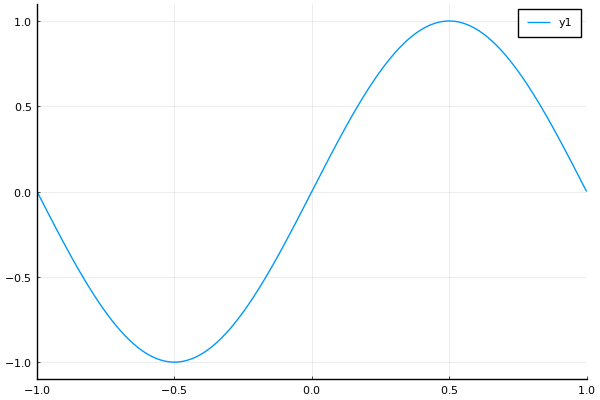

In [52]:
setinitialdata!(t_sim.up,t_sim.xp,t_sim.m,t_sim.h)

nref = 25 # Oversampling for plotting
uplot = zeros((nx-1)*nref+1)
xplot = LinRange(XL,XR,(nx-1)*nref+1)

uex = zeros((nx-1)*nref+1)
primal2plot1d!(uex,t_sim.up,t_sim.Hmat,nref)
plot(xplot,uex,xlims=(XL,XR),ylims=(-1.1, 1.1))

## Forming the Hermite interpolating polynomial

The first step in evolving the approximate solution to the next half timestep at a dual gridpoint $x_{i+\frac{1}{2}}$ is to form a degree $(2m+1)$ polynomial

$$
\begin{equation}
p_{i-\frac{1}{2}}(x) = \sum_{l = 0}^{2m+1} c_l \left( \frac{x - x_{i-\frac{1}{2} }}{h_x}\right)^l,\ \  x \in [x_{i-1},x_{i}], \ \ i = 1,\ldots,n_x,
\end{equation}
$$

from the polynomials representing the initial data at the two nearby primal gridpoints. That is, the coefficients of the new polynomial are determined by insisting that it interpolates the nearby polynomials. Functionally, this amounts to applying the linear map corresponding to Hermite interpolation, say $A$, to the nearby polynomials to find $p_{i-\frac{1}{2}} = A(p_{i-1},p_{i})$. In the code this just corresponds to assembling the nearby coefficients into a $(2m+2) \times 1 $ vector which is multiplied by a matrix `Hmat` (stored in the simulation struct) corresponding to $A$. This can for example be done by the following from inside Chides  

``` Julia
function taylor_to_hermite1d!(uhermite,utaylor,Hmat::Array{Float64,2},m::Int64)
  for j = 1:2*m+2
    @inbounds uhermite[j] = 0.0
  end
  for i = 1:m+1
    for j = 1:2*m+2
      @inbounds uhermite[j] += Hmat[j,i]*utaylor[i,1]+Hmat[j,m+1+i]*utaylor[i,2]
    end
  end
end
```

## Evolving the Hermite interpolating polynomial

To evolve the above polynomial we consider the space-time approximation

$$
\begin{equation}
p^n_{i-\frac{1}{2}}(x,t) = \sum_{l=0}^{2m+1} \sum_{s=0}^{q} d_{ls} \left( \frac{x - x_{i+\frac{1}{2}} }{h_x}\right)^l \left( \frac{t - t_n }{\Delta t}\right)^s,
\end{equation}
$$

which when evaluated at time $t = t_n$ reduces to

$$
\begin{equation}
p_{i-\frac{1}{2}}(x,t_n) = \sum_{l = 0}^{2m+1} d_{l0} \left( \frac{x - x_{i-\frac{1}{2} }}{h_x}\right)^l,\ \  x \in [x_{i-1},x_{i}], \ \ i = 1,\ldots,n_x,
\end{equation}
$$

and we thus have $d_{l0} = c_l$.

To find the remaining coefficients $d_{ls}, s > 0$ we will use the PDE. In particular we will insist that the approximation $p_{i-\frac{1}{2}}(x,t)$ satisfies the PDE at $(x^\ast,t_n)$. For notational convenience consider the approximation at one dual gridpoint, say $x^\ast$ and denote it by $p(x^\ast,t_n)$. Then we have that

$$
\begin{eqnarray}
  \frac{\partial p(x^\ast,t_n)}{\partial x} = \frac{d_{10}}{h_x},\\
  \frac{\partial p(x^\ast,t_n)}{\partial t} = \frac{d_{01}}{\Delta t},
\end{eqnarray}
$$

thus from the PDE we find that we may express the first time-derivative in the Taylor series

$$
\begin{equation}
  \frac{\partial p(x^\ast,t_n)}{\partial t} = a \frac{\partial p(x^\ast,t_n)}{\partial x} \ \ \Rightarrow \ \ d_{01} = a \frac{{\Delta t}}{h_x} d_{10}.
\end{equation}
$$

By repeated differentiation in space and time of the PDE

$$
\begin{equation}
  \frac{\partial^{s+l} u}{\partial t^s \partial^l} = a \frac{\partial^{s-1+l+1} u}{\partial t^{s-1} \partial x^{l+1}},
\end{equation}
$$

which upon replacing \(u\) with \(p\) at \((x^\ast,t_n)\) yields the recursion relation:

$$
\begin{equation}
  d_{sl} = a \frac{{\Delta t}}{h_x} \frac{l+1}{s} d_{s-1,l+1},, \ \ s = 1,\ldots, \ \ l = 0,\ldots,
\end{equation}
$$

specifying all time derivatives in the Taylor series in terms of spatial derivatives. This recursion is implemented in:

In [53]:
function pdeupdate!(uhinterp::Array{Float64,1},uspacetime::Array{Float64,2},sim)
    m = sim.m
    q = sim.q
    uspacetime[1:2*m+2,1] .= uhinterp
    a = -1.0
    cflx  = 1*sim.dt/sim.h
    for idt=1:q
        for idx=0:2*m+1-idt
            uspacetime[1+idx,1+idt] = cflx/idt*(idx+1)*uspacetime[1+idx+1,1+idt-1]
        end
    end
    # Add up the Taylor series for the function and m first derivatives
    # at the next half step.
    dfact = 1.0
    for l=1:q
        dfact *= 0.5
        for i = 1:m+1
            uhinterp[i] += dfact*uspacetime[i,1+l]
        end
    end
end

pdeupdate! (generic function with 1 method)

In the second half of ` pdeupdate!` all the time-coefficients are available and we can evaluate the approximation $p(x,t)$ at a later time $(x^\ast,t_n+\frac{\Delta t}{2})$ for the first $m$ spatial derivatives yielding the new approximation of $u(x,t_{n+\frac{1}{2}})$:

$$
\begin{equation}
     u(x,t_{n+\frac{1}{2}}) \approx  p^n_{i-\frac{1}{2}}(x) = \sum_{l=0}^{m} \sum_{s=0}^{q} {\tilde{c}}_{l} \left( \frac{x - x_{i+\frac{1}{2}} }{h_x}\right)^l,  \ \  x \in [x_{i-1},x_{i}], \ \ i = 1,\ldots,n_x,
\end{equation}
$$

where the new coefficients $\tilde{c}_l$ are

$$
\begin{equation}
  \tilde{c}_l = \sum_{s = 0}^{q}  d_{ls} \left( \frac{1}{2} \right)^s, \ \  l =0,\ldots,m. 
\end{equation}
$$

Note that we only return the $m+1$ first coefficients.

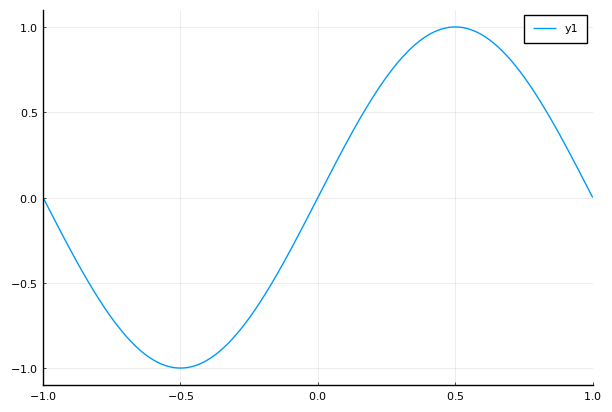

┌ Info: Saved animation to 
│   fn = /Users/appelo/.julia/dev/Chides/examples/transport_solution.gif
└ @ Plots /Users/appelo/.julia/packages/Plots/vsE7b/src/animation.jl:104


In [58]:
anim = @animate for it = 1:t_sim.nt
   evolvep2d_1d_scalar!(t_sim.ud,t_sim.up,t_sim.utaylor,t_sim.uhinterp,t_sim.Hmat,t_sim.m,t_sim.nx,t_sim)
   evolved2p_1d_scalar!(t_sim.up,t_sim.ud,t_sim.utaylor,t_sim.uhinterp,t_sim.Hmat,t_sim.m,t_sim.nx,t_sim)
   if mod(it,1) == 0
      primal2plot1d!(uplot,t_sim.up,t_sim.Hmat,nref)
      pl = plot(xplot,uplot,xlims=(XL,XR),ylims=(-1.1, 1.1))
   end
end
gif(anim, string(@__DIR__,"/transport_solution.gif"), fps = 6)
primal2plot1d!(uplot,t_sim.up,t_sim.Hmat,nref);
#plot(xplot,uplot,xlims=(XL,XR),ylims=(-1.1, 1.1))

In [61]:
maximum(abs.(uplot.-uex))

1.812599224049194e-7

Second half timestep and boundary conditions
--------------------------------------------

The second half timestep follows the same procedure as described above:

> 1.  Form an interpolating polynomial
>
>     ``` {.sourceCode .fortran}
>     ! second half step
>     ! Same thing as above but we now update
>     ! the interor of u
>     t = t + 0.5d0*dt
>     DO i = 1,nx-1
>        tcofs = 0.d0
>        udata(0:m)       = uh(:,1,i)
>        udata(m+1:2*m+1) = uh(:,1,i+1)
>        tcofs(0:2*m+1,0,1) = MATMUL(Aintx,udata)
>     ```
>
> 2.  Then use the PDE and update the approximation at the full timestep
>
>     ``` {.sourceCode .fortran}
>     CALL pde(tcofs,2*m+1,q,nvar,cflx,etax,x(i),t)
>
>      ! Add up the Taylor series
>      DO idx=0,m
>         u(idx,1,i)=tcofs(idx,0,1)
>         dfact=1.d0
>         DO l=1,q
>            dfact=dfact*.5d0
>            u(idx,1,i)=u(idx,1,i) &
>                 +dfact*tcofs(idx,l,1)
>         END DO
>      END DO
>     END DO
>     ```
>
For this example the boundary conditions are taken to be periodic. This means that the interior update procedure can be applied on the boundary as well, with the slight difference that when the interpolating polynomial is formed, data ''from outside the domain'' is replaced by the periodic copy:

``` {.sourceCode .fortran}
! now the left and right bcs
! left
tcofs=0.d0
udata(0:m)=uh(:,1,nx)
udata(m+1:2*m+1)=uh(:,1,1)
tcofs(0:2*m+1,0,1)=MATMUL(Aintx,udata)
CALL pde(tcofs,2*m+1,q,nvar,cflx,etax,x(0),t)
! Add up the Taylor series
DO idx=0,m
   u(idx,1,0)=tcofs(idx,0,1)
   dfact=1.d0
   DO l=1,q
      dfact=dfact*.5d0
      u(idx,1,0)=u(idx,1,0) &
           +dfact*tcofs(idx,l,1)
   END DO
END DO
! Right
u(:,:,nx)=u(:,:,0)
```


Compiling and Running the program
---------------------------------

In the directory `chides/transport/1D` there is a simple `makefile` that can be used to compile the program by simply typing `make` in a terminal window. This assumies you are standing in the directory `chides/transport/1D` and that your system has `gfortran` installed. If you are using another compiler simply change the makefile.

If you are successful in building the solver you should have an executable named `herm1d.x` that you can run.


Displaying the results
----------------------

After running the program you should see something like:

``` {.sourceCode .none}
bash-3.2$ ./herm1d.x 
     Space step,     Max-error
     5.00000E-02     6.60343E-10
```

The program should also have generated a number of snapshots of the solution, `u0000000.txt`, `u0000001.txt`, etc. These can be displayed in Matlab using the script `plot_sol.m`.

Changing the order and number of gridpoints
-------------------------------------------

All the parameters associated with a simulation are contained in the top block of the `pdemodule` (residing in `transport1d.f90`):

``` {.sourceCode .fortran}
MODULE pdemodule
 !
 !
 !  Problem setup for solving 1d transport equation:
 !  u_t = a u_x
 !  With periodic boundary conditions
 !
 ! 
 IMPLICIT NONE
 INTEGER, PARAMETER :: m = 3        ! spatial order 2m+1
 INTEGER, PARAMETER :: q = 2*m+2    ! terms in the Taylor series
 INTEGER, PARAMETER :: nx = 20      ! Discretization uses nx+1 points from xl to xr 
 INTEGER, PARAMETER :: nxp = 500    ! Number of points in the output 

 DOUBLE PRECISION, PARAMETER :: CFL = 0.95d0 ! Ratio dt/h
 INTEGER, PARAMETER :: nout = 1     ! output the solution every nout times
 INTEGER, PARAMETER :: nvar = 1     ! 

 DOUBLE PRECISION, PARAMETER :: a = 1.0d0 ! Wave speed 

 DOUBLE PRECISION, PARAMETER :: ttot = 10.0d0 ! Final time
 DOUBLE PRECISION, PARAMETER :: xl = 0.0d0   ! Domain boundaries
 DOUBLE PRECISION, PARAMETER :: xr = 1.0d0
 ! 
 ! Other constants
 DOUBLE PRECISION, PARAMETER :: pi = 3.1415926535897932385d0
 DOUBLE PRECISION, PARAMETER :: freq = 2.d0
 ! 
CONTAINS
```

This is where you would change the order and the number of gridpoints etc.
